# Practical Assignment 1 — Part I
CNN on CIFAR-10 (goal: mCA ≥ 85%, max. 6 convolutional layers).

## 1. Imports

In [ ]:
!pip install -q datasets

import torch
import torch.nn as nn
import torchvision.transforms as tt
from torch.utils.data import DataLoader, random_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import Dataset
from PIL import Image
from tqdm.auto import tqdm
from datasets import load_dataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


## 2. Dataset
CIFAR-10 (50 000 train / 10 000 test images, 32×32, 10 classes), downloaded from Hugging Face (the official server is very slow).
80/20 train/validation split. Data augmentation (random crop + horizontal flip) is applied only to the training images.

In [ ]:
hf = load_dataset('uoft-cs/cifar10')

# convert to numpy once, so that training is fast
train_images = np.stack([np.array(img) for img in hf['train']['img']])
train_labels = np.array(hf['train']['label'])
test_images  = np.stack([np.array(img) for img in hf['test']['img']])
test_labels  = np.array(hf['test']['label'])
classes = hf['train'].features['label'].names

class CifarDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), int(self.labels[i])

mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)

train_transform = tt.Compose([
    tt.RandomCrop(32, padding=4),
    tt.RandomHorizontalFlip(),
    tt.ToTensor(),
    tt.Normalize(mean, std),
])
test_transform = tt.Compose([
    tt.ToTensor(),
    tt.Normalize(mean, std),
])

training_data       = CifarDataset(train_images, train_labels, train_transform)
training_data_noaug = CifarDataset(train_images, train_labels, test_transform)
testing_data        = CifarDataset(test_images,  test_labels,  test_transform)

n_train = int(len(training_data) * 0.8)
n_val   = len(training_data) - n_train

# same seed -> the same images go to train and to validation in both splits
train_set, _ = random_split(training_data,       [n_train, n_val], generator=torch.Generator().manual_seed(42))
_, val_set   = random_split(training_data_noaug, [n_train, n_val], generator=torch.Generator().manual_seed(42))

print(classes)
print(len(train_set), len(val_set), len(testing_data))

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
40000 10000 10000


## 3. Network
Changes compared to the baseline (Fig. 1):
* 6 convolutional layers (3×3), each followed by Batch Normalization and ReLU;
* Max-pooling after every 2 convolutional layers (32×32 → 16×16 → 8×8 → 4×4);
* Dropout after each block and in the classifier;
* 2 fully-connected layers.

In [ ]:
class ImprovedCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # block 1: 3x32x32 -> 64x16x16
            nn.Conv2d(3, 64, 3, padding=1),    nn.BatchNorm2d(64),  nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),   nn.BatchNorm2d(64),  nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.1),
            # block 2: 64x16x16 -> 128x8x8
            nn.Conv2d(64, 128, 3, padding=1),  nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.2),
            # block 3: 128x8x8 -> 256x4x4
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.3),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256), nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print(ImprovedCNN())

ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.1, inplace=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout(p=0.2, 

## 4. Evaluation metrics
mCA (mean-Class Accuracy), Precision, Recall, F1-Score (macro average) and confusion matrix.

In [ ]:
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * len(labels)
            all_preds.append(outputs.argmax(1).cpu())
            all_labels.append(labels.cpu())
    preds  = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()

    cm = confusion_matrix(labels, preds)
    mca = np.mean(cm.diagonal() / cm.sum(axis=1))      # mean of Correct_i / Total_i
    return {
        'loss': total_loss / len(labels),
        'mCA': mca,
        'Precision': precision_score(labels, preds, average='macro'),
        'Recall': recall_score(labels, preds, average='macro'),
        'F1': f1_score(labels, preds, average='macro'),
        'cm': cm,
    }

## 5. Training

In [ ]:
def train(config):
    torch.manual_seed(42)
    train_loader = DataLoader(train_set, batch_size=config['batch_size'], shuffle=True, num_workers=0)
    val_loader   = DataLoader(val_set, batch_size=256, num_workers=0)

    model = ImprovedCNN().to(device)
    if config['optimizer'] == 'SGD':
        optimizer = torch.optim.SGD(model.parameters(), lr=config['lr'], momentum=0.9, weight_decay=5e-4)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config['epochs'])

    history = {'train_loss': [], 'val_loss': [], 'val_mCA': []}
    for epoch in range(config['epochs']):
        model.train()
        running_loss = 0
        for images, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}', leave=False):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(labels)
        scheduler.step()

        val = evaluate(model, val_loader)
        history['train_loss'].append(running_loss / len(train_set))
        history['val_loss'].append(val['loss'])
        history['val_mCA'].append(val['mCA'])
        print(f"Epoch {epoch+1}/{config['epochs']} | train loss {history['train_loss'][-1]:.4f} "
              f"| val loss {val['loss']:.4f} | val mCA {val['mCA']:.4f}")
    return model, history

## 6. Four hyperparameter combinations
All runs: 30 epochs, cosine learning-rate scheduler, weight decay 5e-4, cross-entropy loss.

In [ ]:
configs = {
    'Config 1': {'optimizer': 'SGD',  'lr': 0.05,  'batch_size': 128, 'epochs': 30},
    'Config 2': {'optimizer': 'SGD',  'lr': 0.005, 'batch_size': 128, 'epochs': 30},
    'Config 3': {'optimizer': 'SGD',  'lr': 0.05,  'batch_size': 512, 'epochs': 30},
    'Config 4': {'optimizer': 'Adam', 'lr': 0.001, 'batch_size': 128, 'epochs': 30},
}

test_loader = DataLoader(testing_data, batch_size=256, num_workers=0)
histories, test_results = {}, {}

for name, config in configs.items():
    print(f'===== {name}: {config} =====')
    model, history = train(config)
    histories[name] = history
    test_results[name] = evaluate(model, test_loader)
    torch.save(model.state_dict(), f'{name.replace(" ", "_")}.pt')   # save the trained model

===== Config 1: {'optimizer': 'SGD', 'lr': 0.05, 'batch_size': 128, 'epochs': 30} =====


Epoch 1:   0%|          | 0/313 [00:00<?, ?it/s]

Epoch 1/30 | train loss 2.0533 | val loss 1.8596 | val mCA 0.2752


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 2:   0%|          | 0/313 [00:00<?, ?it/s]

...

Epoch 28/30 | train loss 0.1982 | val loss 0.2957 | val mCA 0.9052


Epoch 29:   0%|          | 0/313 [00:00<?, ?it/s]

Epoch 29/30 | train loss 0.1919 | val loss 0.2932 | val mCA 0.9064


Epoch 30:   0%|          | 0/313 [00:00<?, ?it/s]

Epoch 30/30 | train loss 0.1875 | val loss 0.2932 | val mCA 0.9063


## 7. Results

In [ ]:
# Table with the test metrics of the 4 configurations
table = pd.DataFrame({name: {k: r[k] for k in ['mCA', 'F1', 'Precision', 'Recall']}
                      for name, r in test_results.items()}).T
print(table.round(4))

             mCA      F1  Precision  Recall
Config 1  0.9015  0.9011     0.9011  0.9015
Config 2  0.8694  0.8687     0.8689  0.8694
Config 3  0.8755  0.8750     0.8753  0.8755
Config 4  0.9012  0.9008     0.9008  0.9012


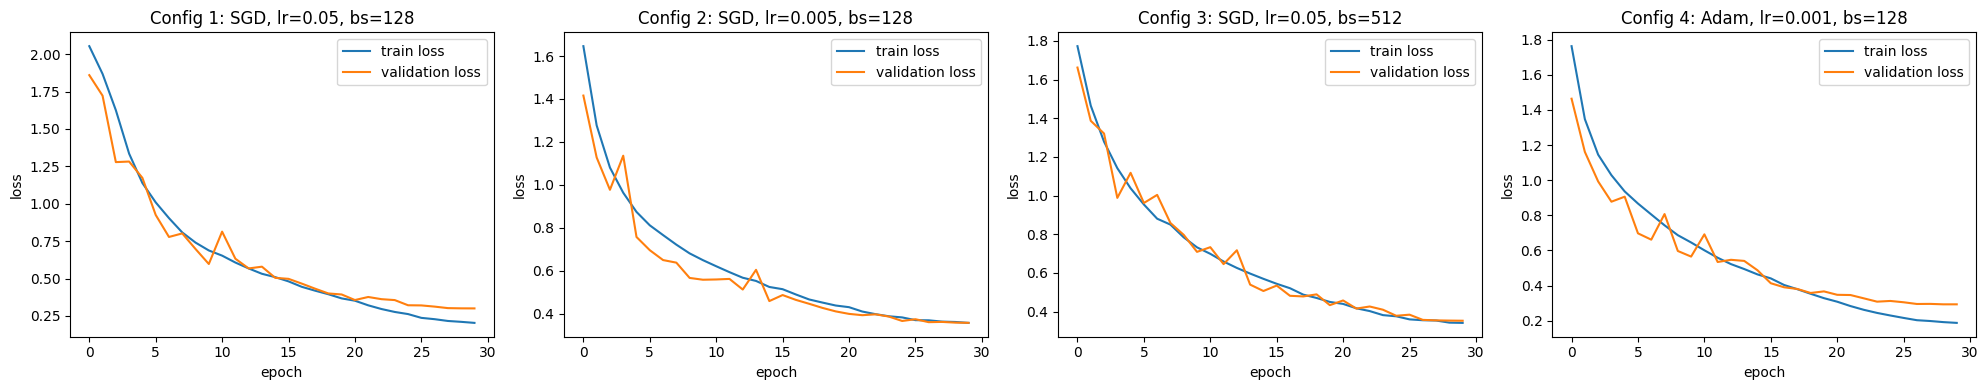

In [ ]:
# Loss curves of the 4 configurations
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h['train_loss'], label='train loss')
    ax.plot(h['val_loss'], label='validation loss')
    ax.set_title(f'{name}: {configs[name]["optimizer"]}, lr={configs[name]["lr"]}, bs={configs[name]["batch_size"]}')
    ax.set_xlabel('epoch'); ax.set_ylabel('loss'); ax.legend()
plt.tight_layout()
plt.show()

Best configuration: Config 4 | test mCA = 0.9012


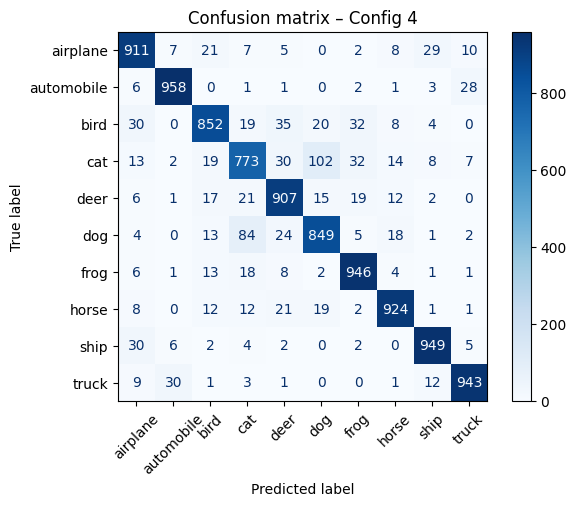

In [ ]:
# Confusion matrix of the best configuration (chosen by the best validation mCA)
best = max(histories, key=lambda n: max(histories[n]['val_mCA']))
print('Best configuration:', best, '| test mCA =', round(test_results[best]['mCA'], 4))

ConfusionMatrixDisplay(test_results[best]['cm'], display_labels=classes).plot(xticks_rotation=45, cmap='Blues')
plt.title(f'Confusion matrix – {best}')
plt.show()